# 05 Time series analysis and forecasting: monthly and daily Delhi AQI

**Syllabus units:** Forecasting (7 marks) and Time series analysis (8 marks). **Tutorial item 5.**
This is the genuinely *predictive* part of the project: unlike notebooks 03-04, no same-day pollutant readings are
used to "predict" AQI; every forecast uses only the past.

**Design.**
* Monthly mean AQI, January 2015 to December 2019 (60 months). Train 2015-01 to 2019-06 (54 months), test
  2019-07 to 2019-12 (6 months), as fixed in `src/utils.py`.
* Because 6 test months is a small sample, models are also compared by **rolling-origin evaluation**: 19 forecast
  origins (December 2017 to June 2019), each forecasting 1 to 6 months ahead with only the data available then.
* The chosen model is refitted on all 60 months and forecasts January to June 2020, which is then compared with
  what actually happened during the COVID-19 lockdown.
* Part G adds a daily ARMA model for **next-day** AQI forecasting.

**Outputs:** `outputs/forecast_monthly.csv` (read by the app), `outputs/tables/forecast_comparison.csv`.

In [1]:
import sys, itertools, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.stats.diagnostic import acorr_ljungbox
from src.utils import *
set_plot_style()
warnings.filterwarnings("ignore")

daily = load_clean(index_by_date=True)
monthly = daily[["AQI", "PM2.5", "PM10", "NO2", "CO", "Poor_Flag"]].resample("MS").mean()
monthly.index.freq = "MS"
y = monthly["AQI"]
train = y[:TS_TRAIN_END]
test = y[TS_TEST_START:]
H = len(test)
print(f"monthly series: {len(y)} months | train {len(train)} ({train.index[0]:%Y-%m} to {train.index[-1]:%Y-%m}) "
      f"| test {H} ({test.index[0]:%Y-%m} to {test.index[-1]:%Y-%m})")

def rmse(a, f): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))

monthly series: 60 months | train 54 (2015-01 to 2019-06) | test 6 (2019-07 to 2019-12)


## Part A: Look at the series

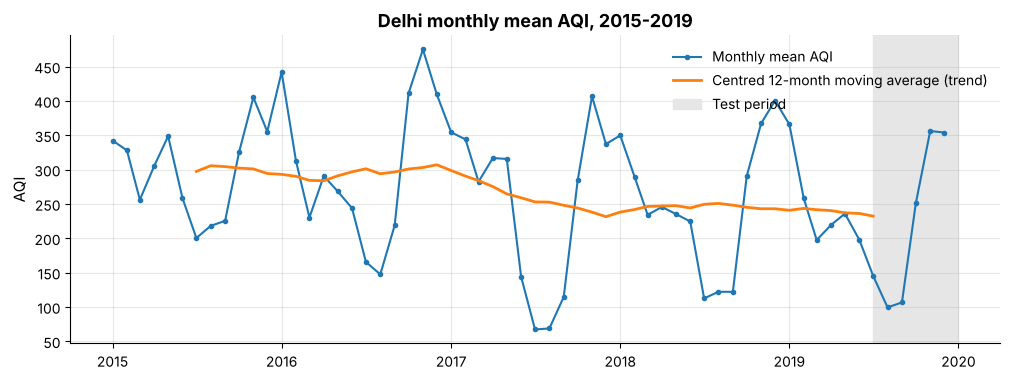

In [2]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.index, y, marker="o", ms=3, label="Monthly mean AQI")
ax.plot(y.index, y.rolling(12, center=True).mean(), lw=2, label="Centred 12-month moving average (trend)")
ax.axvspan(test.index[0], test.index[-1] + pd.offsets.MonthEnd(0), color="0.9", label="Test period")
ax.set(title="Delhi monthly mean AQI, 2015-2019", ylabel="AQI"); ax.legend()
save_figure(fig, "05_monthly_series"); plt.show()

strength of seasonality = 0.85, strength of trend = 0.32 (0 = none, 1 = maximal)
seasonal indices (classical additive decomposition):
Jan    111.0
Feb     35.0
Mar    -27.0
Apr      7.0
May      4.0
Jun    -57.0
Jul   -139.0
Aug   -136.0
Sep   -104.0
Oct     55.0
Nov    143.0
Dec    107.0


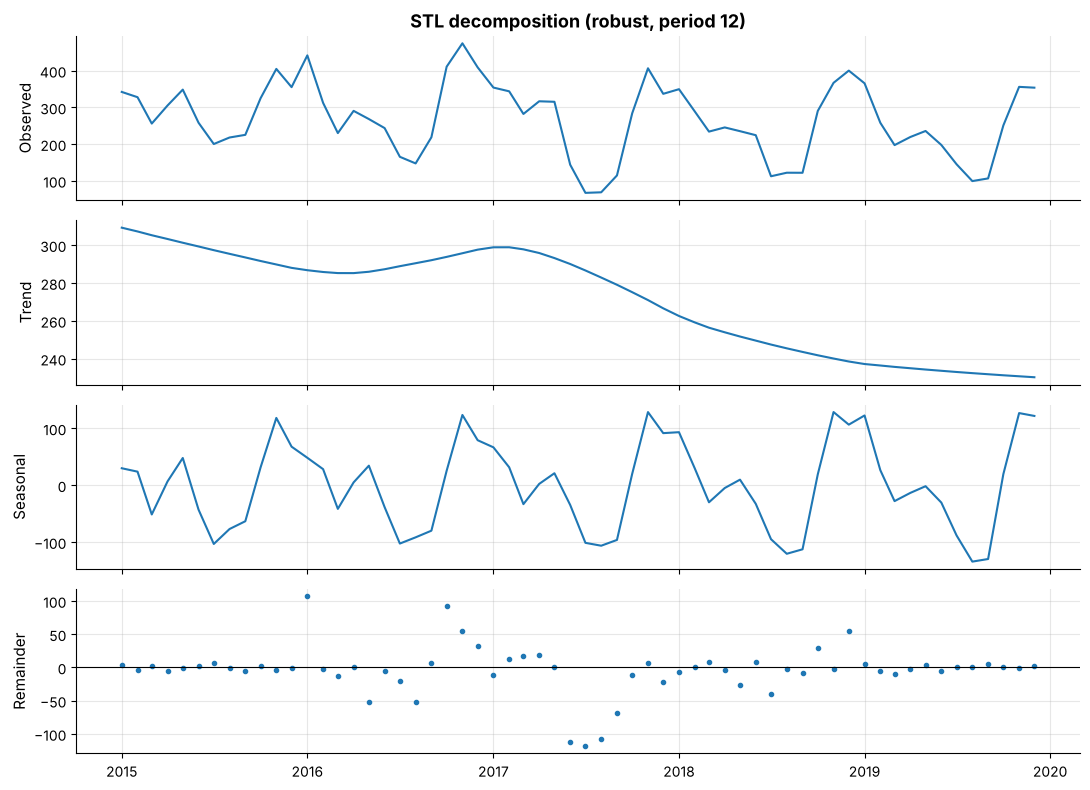

In [3]:
stl = STL(y, period=12, robust=True).fit()
dec = seasonal_decompose(y, model="additive", period=12)
fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
ax[0].plot(y); ax[0].set_ylabel("Observed")
ax[1].plot(stl.trend); ax[1].set_ylabel("Trend")
ax[2].plot(stl.seasonal); ax[2].set_ylabel("Seasonal")
ax[3].plot(stl.resid, marker=".", ls=""); ax[3].axhline(0, color="k", lw=.8); ax[3].set_ylabel("Remainder")
ax[0].set_title("STL decomposition (robust, period 12)")
plt.tight_layout(); save_figure(fig, "05_stl"); plt.show()
F_season = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
F_trend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"strength of seasonality = {F_season:.2f}, strength of trend = {F_trend:.2f} (0 = none, 1 = maximal)")
print("seasonal indices (classical additive decomposition):")
print(dec.seasonal[:12].set_axis([f"{m:%b}" for m in dec.seasonal.index[:12]]).round(0).to_string())

## Part B: Stationarity and autocorrelation
ARMA models need a *stationary* series (constant mean and variance, autocorrelation depending only on the lag).
Two complementary tests are used: **ADF** (null: unit root, non-stationary) and **KPSS** (null: stationary).

In [4]:
def stat_tests(s, name):
    s = s.dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    return {"Series": name, "n": len(s), "ADF p": adf_p, "KPSS p": kpss_p,
            "Verdict": "stationary" if adf_p < .05 and kpss_p > .05 else
                       ("non-stationary" if adf_p >= .05 and kpss_p <= .05 else "inconclusive")}

st_tab = pd.DataFrame([stat_tests(train, "AQI (level)"),
                       stat_tests(train.diff(), "first difference"),
                       stat_tests(train.diff(12), "seasonal difference (lag 12)"),
                       stat_tests(train.diff(12).diff(), "seasonal + first difference")])
st_tab.round(3)

,Series,n,ADF p,KPSS p,Verdict
0,AQI (level),54,0.861,0.1,inconclusive
1,first difference,53,0.000,0.1,stationary
2,seasonal difference (lag 12),42,0.000,0.1,stationary
3,seasonal + first difference,41,0.000,0.1,stationary


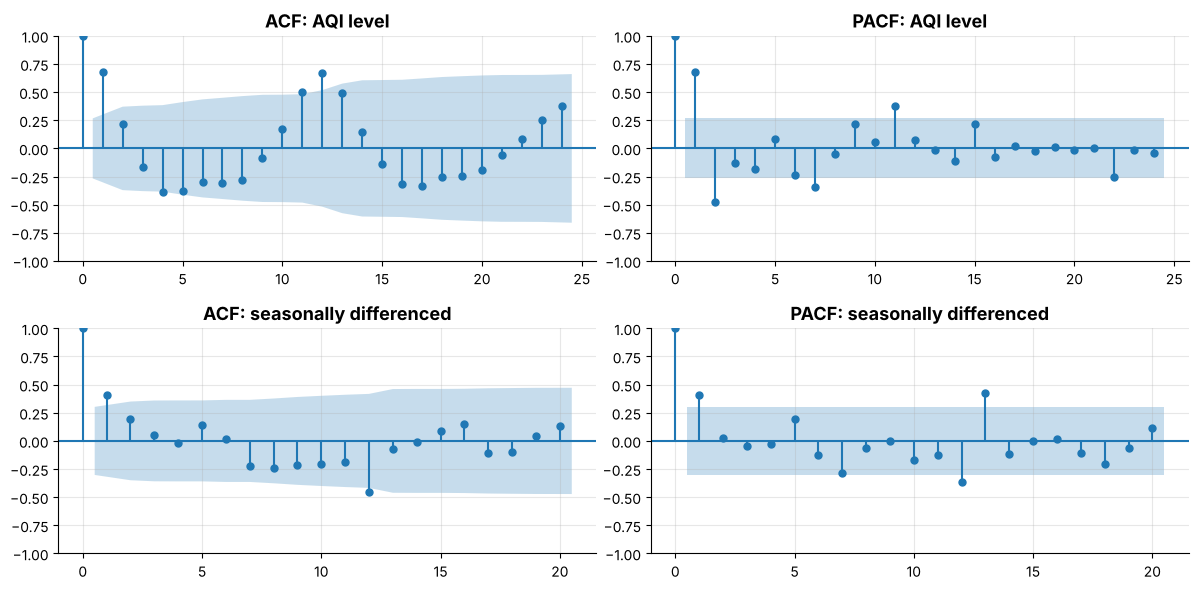

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6))
plot_acf(train, lags=24, ax=ax[0, 0]); ax[0, 0].set_title("ACF: AQI level")
plot_pacf(train, lags=24, ax=ax[0, 1], method="ywm"); ax[0, 1].set_title("PACF: AQI level")
plot_acf(train.diff(12).dropna(), lags=20, ax=ax[1, 0]); ax[1, 0].set_title("ACF: seasonally differenced")
plot_pacf(train.diff(12).dropna(), lags=20, ax=ax[1, 1], method="ywm"); ax[1, 1].set_title("PACF: seasonally differenced")
plt.tight_layout(); save_figure(fig, "05_acf_pacf"); plt.show()

**What the series looks like, and what that means for the models**

* **Seasonality dominates:** STL gives a seasonal strength of 0.85 and a trend strength of 0.32. The classical
  seasonal indices run from +143 in November and +111 in January to -139 in July: a swing of about 280 AQI points
  between the post-monsoon peak and the monsoon trough.
* **Trend:** the 12-month moving average falls from about 300 (2015-16) to about 230 (2019).
* **Stationarity:** on the level series ADF cannot reject a unit root (p = 0.86). (KPSS p = 0.10 is the edge of its
  lookup table, so the two tests disagree and the verdict is "inconclusive".) After a first difference, a seasonal
  difference, or both, ADF rejects the unit root (p < 0.001) and KPSS does not reject stationarity, so d = 1 is used
  for the non-seasonal ARIMA and D = 1 for the seasonal model.
* **ACF/PACF:** the level ACF swings with a 12-month period (+0.68 at lag 1 and +0.67 at lag 12, negative at lags 3-9), the
  signature of seasonality. After seasonal differencing the PACF cuts off after lag 1 and the ACF decays, pointing to
  an AR(1) term, and the ACF spike of -0.46 at lag 12 points to a seasonal MA term. This is what the AIC grid selects: **SARIMA(1,0,0)(0,1,1)₁₂**
  (AIC 444.0). The best non-seasonal model is ARIMA(2,1,2).
* **A revealing detail:** the seasonal MA coefficient is -0.998, on the boundary of invertibility, with a huge
  standard error. A seasonal MA of -1 exactly cancels the seasonal difference, which means the seasonality is
  **deterministic** (the same calendar pattern every year) rather than a random walk. That points directly to a
  model with fixed month effects: the causal regression below.
* SARIMA residuals pass the Ljung-Box test (p = 0.94 at lag 6, 0.61 at lag 12): no autocorrelation is left.

## Part C: Candidate forecasting models
Each model is a function `f(history, h)` that sees only the history and returns h forecasts, so the same code is
used for the test split and for rolling-origin evaluation.

| Family | Model | Idea |
| --- | --- | --- |
| Benchmarks | Naive | next month = last month |
| | Seasonal naive | next July = last July |
| Moving average | MA(3) | mean of the last 3 months |
| | Seasonal moving average | mean of the same month in the previous 3 years |
| Exponential smoothing | Simple (SES) | weighted average, weights decay geometrically (α) |
| | Holt-Winters additive, damped trend | level + damped trend + additive monthly effects |
| ARIMA family | ARIMA(p,d,q) | non-seasonal Box-Jenkins model |
| | SARIMA(p,d,q)(P,D,Q)₁₂ | adds seasonal AR/MA/differencing at lag 12 |
| Causal (regression) | Trend + month + lagged pollutants | AQI explained by a time trend, month dummies and pollutant levels 6 months earlier |
| | Same, with AR(1) errors | dynamic regression: lets this month's surprise carry into the next |
| Multivariate | VAR on AQI, PM2.5, PM10, NO2 | each series explained by lags of all four (deseasonalised) |

In [6]:
def f_naive(h_, h): return np.repeat(h_.iloc[-1], h)
def f_snaive(h_, h): return h_.iloc[-12:].values[:h] if h <= 12 else np.tile(h_.iloc[-12:].values, 2)[:h]
def f_ma3(h_, h): return np.repeat(h_.iloc[-3:].mean(), h)
def f_sma(h_, h):
    out = []
    for i in range(1, h + 1):
        same = [h_.iloc[-12 * k + i - 1] for k in (1, 2, 3) if len(h_) >= 12 * k - i + 1]
        out.append(np.mean(same))
    return np.array(out)
def f_ses(h_, h): return SimpleExpSmoothing(h_, initialization_method="estimated").fit().forecast(h).values
def f_hw(h_, h):
    return ExponentialSmoothing(h_, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12,
                                initialization_method="estimated").fit().forecast(h).values

### ARIMA order selection (Box-Jenkins)
Orders are chosen on the training data by AIC over a small grid, with the differencing orders fixed by the
stationarity tests (AIC is only comparable between models with the same differencing).

In [7]:
def grid_arima(series, d, seasonal, D=0):
    best, rows = None, []
    PQ = [(0, 0), (1, 0), (0, 1), (1, 1)] if seasonal else [(0, 0)]
    for p, q in itertools.product(range(3), range(3)):
        for P, Q in PQ:
            try:
                r = SARIMAX(series, order=(p, d, q), seasonal_order=(P, D, Q, 12) if seasonal else (0, 0, 0, 0),
                            trend="c" if (d + D) == 0 else "n").fit(disp=False)
            except Exception:
                continue
            rows.append({"order": (p, d, q), "seasonal": (P, D, Q, 12) if seasonal else "-", "AIC": r.aic, "BIC": r.bic})
            if best is None or r.aic < best[0]:
                best = (r.aic, (p, d, q), (P, D, Q, 12) if seasonal else (0, 0, 0, 0))
    return best, pd.DataFrame(rows).sort_values("AIC")

best_arima, tab_arima = grid_arima(train, d=1, seasonal=False)
best_sarima, tab_sarima = grid_arima(train, d=0, seasonal=True, D=1)
print("best ARIMA :", best_arima[1], f"AIC {best_arima[0]:.1f}")
print("best SARIMA:", best_sarima[1], best_sarima[2], f"AIC {best_sarima[0]:.1f}")
tab_sarima.head(6).round(1)

best ARIMA : (2, 1, 2) AIC 595.7
best SARIMA: (1, 0, 0) (0, 1, 1, 12) AIC 444.0


,order,seasonal,AIC,BIC
14,"(1, 0, 0)","(0, 1, 1, 12)",444.0,449.2
15,"(1, 0, 0)","(1, 1, 1, 12)",444.3,451.2
13,"(1, 0, 0)","(1, 1, 0, 12)",445.7,450.9
18,"(1, 0, 1)","(0, 1, 1, 12)",445.8,452.8
26,"(2, 0, 0)","(0, 1, 1, 12)",445.8,452.8
19,"(1, 0, 1)","(1, 1, 1, 12)",446.3,454.9


In [8]:
ARIMA_ORDER, SARIMA_ORDER, SARIMA_SEAS = best_arima[1], best_sarima[1], best_sarima[2]

def f_arima(h_, h):
    return SARIMAX(h_, order=ARIMA_ORDER, trend="n").fit(disp=False).forecast(h).values
def f_sarima(h_, h):
    tr = "c" if (SARIMA_ORDER[1] + SARIMA_SEAS[1]) == 0 else "n"
    return SARIMAX(h_, order=SARIMA_ORDER, seasonal_order=SARIMA_SEAS, trend=tr).fit(disp=False).forecast(h).values

sar = SARIMAX(train, order=SARIMA_ORDER, seasonal_order=SARIMA_SEAS).fit(disp=False)
print(sar.summary().tables[1])
lb = acorr_ljungbox(sar.resid[13:], lags=[6, 12], return_df=True)
print("Ljung-Box on SARIMA residuals:\n", lb.round(3))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6409      0.135      4.764      0.000       0.377       0.904
ma.S.L12      -0.9977     92.314     -0.011      0.991    -181.929     179.934
sigma2      1281.9487   1.18e+05      0.011      0.991    -2.3e+05    2.33e+05
Ljung-Box on SARIMA residuals:
     lb_stat  lb_pvalue
6     1.760      0.940
12   10.096      0.608


### Causal (regression-based) forecasting model
AQI_t = β0 + β1·t + Σ γ_m·Month_m + δ·PM10_(t-6) + ε_t. The pollutant enters with a **6-month lag**, so a 6-month
forecast needs no forecast of the pollutant itself. Candidate lagged pollutants are compared by AIC on the training data.

In [9]:
def causal_design(idx, lag_var=None, lag=6, src=monthly):
    t = np.arange(len(src))[src.index.get_indexer(idx)]
    X = pd.DataFrame({"const": 1.0, "trend": t}, index=idx)
    for m in range(2, 13):                       # January is the baseline month
        X[f"m_{m}"] = (idx.month == m).astype(float)
    if lag_var:
        X[f"{lag_var}_lag{lag}"] = src[lag_var].shift(lag).reindex(idx).values
    return X

cands = {}
for v in [None, "PM2.5", "PM10", "NO2", "CO"]:
    Xc_ = causal_design(train.index[6:], v)
    r_ = sm.OLS(train.iloc[6:], Xc_).fit()
    cands["trend + month" + (f" + {v} lag 6" if v else "")] = {"AIC": r_.aic, "adj R2": r_.rsquared_adj,
                                                                 "lag p-value": r_.pvalues.iloc[-1] if v else np.nan}
cand_tab = pd.DataFrame(cands).T.sort_values("AIC")
CAUSAL_VAR = None if cand_tab.index[0] == "trend + month" else cand_tab.index[0].split(" + ")[1].split(" lag")[0]
print("chosen causal specification:", cand_tab.index[0])
cand_tab.round(3)

chosen causal specification: trend + month


,AIC,adj R2,lag p-value
trend + month,498.633,0.850,NaN
trend + month + NO2 lag 6,498.708,0.851,0.246
trend + month + CO lag 6,498.829,0.851,0.262
trend + month + PM10 lag 6,500.036,0.847,0.519
trend + month + PM2.5 lag 6,500.629,0.845,0.961


In [10]:
def f_causal(h_, h, var=None):
    var = CAUSAL_VAR if var is None else var
    start = 6 if var else 0
    Xh = causal_design(h_.index[start:], var)
    r = sm.OLS(h_.iloc[start:], Xh).fit()
    fut = pd.date_range(h_.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
    Xf = causal_design(fut, var, src=monthly.reindex(monthly.index.union(fut)))
    return r.predict(Xf[Xh.columns]).values

cr = sm.OLS(train.iloc[6 if CAUSAL_VAR else 0:], causal_design(train.index[6 if CAUSAL_VAR else 0:], CAUSAL_VAR)).fit()
print(cr.summary().tables[1])
print(f"Durbin-Watson of the causal regression residuals: {sm.stats.durbin_watson(cr.resid):.2f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        408.1848     19.111     21.359      0.000     369.589     446.780
trend         -1.5588      0.340     -4.591      0.000      -2.244      -0.873
m_2          -62.8829     24.449     -2.572      0.014    -112.259     -13.507
m_3         -127.6760     24.456     -5.221      0.000    -177.066     -78.286
m_4          -90.5645     24.468     -3.701      0.001    -139.979     -41.150
m_5          -83.8359     24.484     -3.424      0.001    -133.283     -34.388
m_6         -149.3670     24.506     -6.095      0.000    -198.857     -99.877
m_7         -234.4516     25.930     -9.042      0.000    -286.818    -182.085
m_8         -230.1590     25.932     -8.875      0.000    -282.530    -177.788
m_9         -197.5066     25.939     -7.614      0.000    -249.891    -145.123
m_10         -38.4366     25.950     -1.481      0.1

The Durbin-Watson statistic well below 2 shows that the regression errors are positively autocorrelated: a month
that is worse than its seasonal norm tends to be followed by another. Ordinary least squares then understates the
uncertainty and wastes information. The remedy is a **dynamic regression**: the same trend and month terms, but with
AR(1) errors, u_t = ρ·u_(t-1) + ε_t, estimated by feasible GLS (iterated Cochrane-Orcutt, `GLSAR`). Its
h-step forecast is the regression line plus ρ^h times the last residual, so the latest surprise fades out.

In [11]:
def fit_glsar(h_):
    Xh = causal_design(h_.index, None)
    r = sm.GLSAR(h_, Xh, rho=1).iterative_fit(maxiter=50)
    return r, Xh

def f_causal_ar1(h_, h):
    r, Xh = fit_glsar(h_)
    rho = float(r.model.rho[0])
    last_u = float(h_.iloc[-1] - r.predict(Xh.iloc[[-1]]).iloc[0])
    fut = pd.date_range(h_.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
    base = r.predict(causal_design(fut, None, src=monthly.reindex(monthly.index.union(fut)))[Xh.columns]).values
    return base + last_u * rho ** np.arange(1, h + 1)

dyn, _ = fit_glsar(train)
print(dyn.summary().tables[1])
print(f"estimated AR(1) coefficient of the errors: rho = {dyn.model.rho[0]:.3f}")
print(f"trend: OLS {cr.params['trend']:.2f} (SE {cr.bse['trend']:.2f}) | GLS {dyn.params['trend']:.2f} (SE {dyn.bse['trend']:.2f})")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        431.9456     24.274     17.794      0.000     382.885     481.006
trend         -1.8011      0.526     -3.425      0.001      -2.864      -0.738
m_2          -72.9329     18.335     -3.978      0.000    -109.988     -35.878
m_3         -141.8731     22.205     -6.389      0.000    -186.751     -96.995
m_4         -106.3913     23.696     -4.490      0.000    -154.282     -58.501
m_5         -100.2187     24.294     -4.125      0.000    -149.318     -51.119
m_6         -165.8479     24.527     -6.762      0.000    -215.418    -116.278
m_7         -249.3702     25.752     -9.684      0.000    -301.417    -197.324
m_8         -246.5713     25.904     -9.519      0.000    -298.926    -194.217
m_9         -214.4171     25.694     -8.345      0.000    -266.346    -162.488
m_10         -55.4205     25.087     -2.209      0.0

### Multivariate model: VAR on AQI, PM2.5, PM10 and NO2
A VAR(p) models each series as a linear function of p lags of **all** the series. The strong common seasonal cycle
is removed first (subtracting each calendar month's training mean), so the VAR describes how *deviations from the
usual month* propagate. The lag order is chosen by AIC (capped at 3 because there are only 54 months).

In [12]:
VAR_COLS = ["AQI", "PM2.5", "PM10", "NO2"]

def var_fit(hist_df, maxlags=3):
    clim = hist_df.groupby(hist_df.index.month).mean()
    anom = hist_df - clim.loc[hist_df.index.month].values
    sel = VAR(anom).select_order(maxlags)
    p = max(1, int(sel.aic))
    return VAR(anom).fit(p), clim, anom, sel

def f_var(h_, h):
    hist_df = monthly.loc[h_.index, VAR_COLS]
    res, clim, anom, _ = var_fit(hist_df)
    fc = res.forecast(anom.values[-res.k_ar:], h)[:, 0]
    fut_m = pd.date_range(h_.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS").month
    return fc + clim.loc[fut_m, "AQI"].values

var_res, var_clim, var_anom, var_sel = var_fit(monthly.loc[train.index, VAR_COLS])
print(var_sel.summary())
print(f"chosen lag order p = {var_res.k_ar}; stable: {var_res.is_stable()}")

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       23.22       23.37   1.218e+10       23.28
1       21.22      21.98*   1.647e+09       21.51
2       20.66       22.03   9.544e+08       21.18
3      20.43*       22.40  7.775e+08*      21.18*
-------------------------------------------------
chosen lag order p = 3; stable: True


In [13]:
gc = []
for caused in VAR_COLS:
    for causing in VAR_COLS:
        if caused != causing:
            t_ = var_res.test_causality(caused, [causing], kind="f")
            gc.append({"does": causing, "Granger-cause": caused, "F": t_.test_statistic, "p-value": t_.pvalue})
gc = pd.DataFrame(gc).sort_values("p-value")
save_table(gc.round(4), "var_granger")
gc.round(3)

,does,Granger-cause,F,p-value
3,AQI,PM2.5,12.549,0.000
5,NO2,PM2.5,9.797,0.000
2,NO2,AQI,5.970,0.001
1,PM10,AQI,5.407,0.001
9,AQI,NO2,4.063,0.008
7,PM2.5,PM10,2.783,0.043
10,PM2.5,NO2,2.227,0.087
8,NO2,PM10,2.184,0.092
4,PM10,PM2.5,1.757,0.158
6,AQI,PM10,1.501,0.216


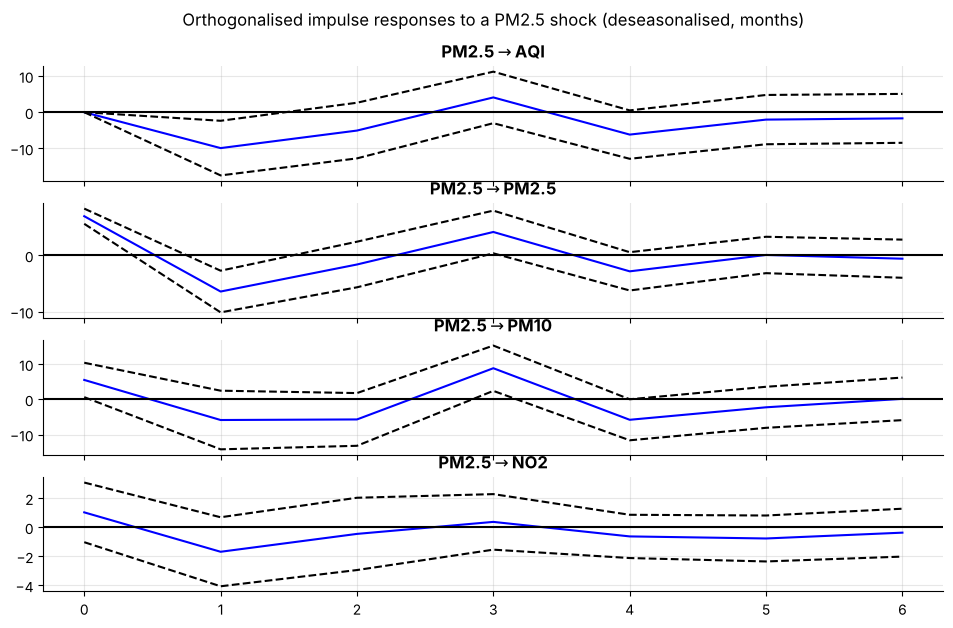

,AQI,PM2.5,PM10,NO2
AQI forecast-error variance from,,,,
h=1,1.000,0.000,0.000,0.000
h=2,0.705,0.100,0.056,0.140
h=3,0.651,0.106,0.112,0.131
h=4,0.569,0.102,0.216,0.113
h=5,0.498,0.111,0.293,0.098
h=6,0.439,0.099,0.344,0.117


In [14]:
irf = var_res.irf(6)
fig = irf.plot(impulse="PM2.5", orth=True, figsize=(10, 6))
fig.suptitle("Orthogonalised impulse responses to a PM2.5 shock (deseasonalised, months)", y=1.02)
save_figure(fig, "05_var_irf"); plt.show()
fevd = var_res.fevd(6)
pd.DataFrame(fevd.decomp[0], columns=VAR_COLS, index=[f"h={i+1}" for i in range(6)]).round(3).rename_axis("AQI forecast-error variance from")

**Causal and multivariate models: findings**

* **Causal regression:** AQI_t = 408.2 - 1.56·t + month effects. The trend is significant (p < 0.001): Delhi's
  monthly AQI fell by about **1.6 points per month, roughly 19 points per year**, after allowing for season. With
  January as baseline, July-August are about 230 points lower; November is the only month above January. Adjusted
  R² = 0.85.
* **Lagged pollutants did not help:** adding PM2.5, PM10, NO2 or CO from 6 months earlier never lowers AIC (best
  lag p-value 0.25). Pollution six months ago carries no information beyond season and trend, so the simpler
  trend + month model is kept. This is a useful negative result.
* **Autocorrelated errors:** Durbin-Watson = 1.08. Feasible GLS (Cochrane-Orcutt) estimates ρ = 0.43 and widens the
  trend's standard error from 0.34 to 0.53 (the trend stays significant). OLS standard errors were too small.
* **VAR:** AIC chooses 3 lags (BIC prefers 1); the system is stable. Granger causality (does the past of X help
  predict Y beyond Y's own past?):
  * NO2 → AQI (p = 0.001) and PM10 → AQI (p = 0.001): unusual NO2 or dust months are followed by unusual AQI months;
  * AQI → PM2.5 and NO2 → PM2.5 (p < 0.001);
  * PM2.5 does **not** Granger-cause AQI (p = 0.22). That is not a contradiction of notebook 03: PM2.5 drives AQI
    *in the same month*, and AQI's own past already contains PM2.5's past.
* **Forecast-error variance decomposition:** at 1 month ahead all AQI uncertainty is its own shock; by 6 months
  ahead PM10 shocks explain 34% and NO2 12%. Dust (PM10) is the main source of medium-term surprises.

## Part D: Test-set comparison (July to December 2019)

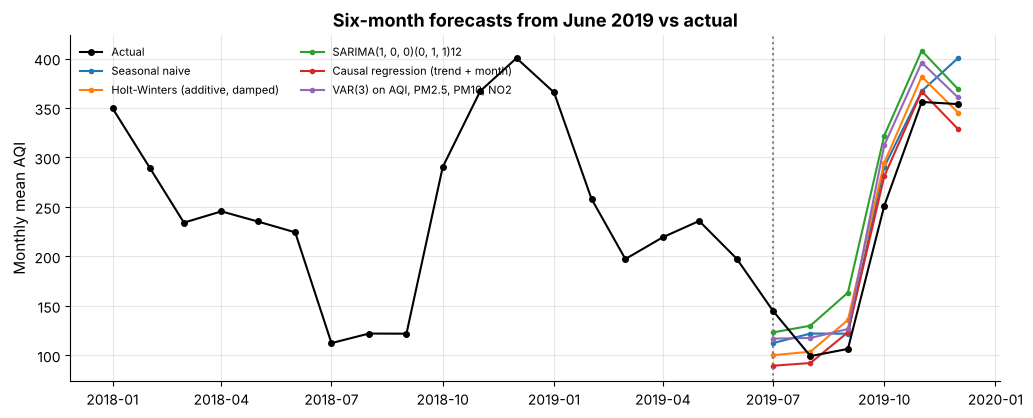

,Test RMSE,Test MAE,Test MAPE %
Causal regression with AR(1) errors,26.31,21.37,12.07
Causal regression (trend + month),29.02,24.16,13.85
"Holt-Winters (additive, damped)",30.31,26.03,14.97
Seasonal naive,30.71,27.95,15.31
"VAR(3) on AQI, PM2.5, PM10, NO2",33.94,29.06,15.70
"SARIMA(1, 0, 0)(0, 1, 1)12",45.86,41.26,24.43
Seasonal moving average (3 yr),47.55,42.46,22.09
"ARIMA(2, 1, 2)",89.28,79.48,55.64
Moving average MA(3),108.37,101.68,60.70
Simple exponential smoothing,110.33,101.68,55.20


In [15]:
MODELS = {"Naive": f_naive, "Seasonal naive": f_snaive, "Moving average MA(3)": f_ma3,
          "Seasonal moving average (3 yr)": f_sma, "Simple exponential smoothing": f_ses,
          "Holt-Winters (additive, damped)": f_hw, f"ARIMA{ARIMA_ORDER}": f_arima,
          f"SARIMA{SARIMA_ORDER}{SARIMA_SEAS[:3]}12": f_sarima,
          "Causal regression (trend + month" + (f" + {CAUSAL_VAR} lag 6)" if CAUSAL_VAR else ")"): f_causal,
          "Causal regression with AR(1) errors": f_causal_ar1,
          f"VAR({var_res.k_ar}) on AQI, PM2.5, PM10, NO2": f_var}
test_fc = {name: f(train, H) for name, f in MODELS.items()}
test_tab = pd.DataFrame({name: {"Test RMSE": rmse(test, fc), "Test MAE": float(np.mean(np.abs(test.values - fc))),
                                "Test MAPE %": mape(test, fc)} for name, fc in test_fc.items()}).T

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y["2018-01":].index, y["2018-01":], "k-o", ms=4, label="Actual", zorder=5)
for name in ["Seasonal naive", "Holt-Winters (additive, damped)", list(MODELS)[7], list(MODELS)[8], list(MODELS)[10]]:
    ax.plot(test.index, test_fc[name], marker=".", label=name)
ax.axvline(test.index[0], color="grey", ls=":")
ax.set(title="Six-month forecasts from June 2019 vs actual", ylabel="Monthly mean AQI"); ax.legend(fontsize=8, ncol=2)
save_figure(fig, "05_test_forecasts"); plt.show()
test_tab.sort_values("Test RMSE").round(2)

## Part E: Rolling-origin evaluation (time-series cross-validation)
Six test points are too few to separate good models from lucky ones. Here every model is refitted at each of 19
origins (December 2017 to June 2019) and forecasts up to 6 months ahead, using only data available at the origin.

In [16]:
origins = pd.date_range("2017-12-01", TS_TRAIN_END, freq="MS")
errs = []
for o in origins:
    hist = y[:o]
    fut = y[o + pd.offsets.MonthBegin():][:H]
    for name, f in MODELS.items():
        fc = f(hist, len(fut))
        for k, (a, b) in enumerate(zip(fut.values, fc), start=1):
            errs.append({"origin": o, "model": name, "h": k, "err": a - b, "ape": abs(a - b) / a * 100})
errs = pd.DataFrame(errs)
roll = errs.groupby("model").agg(**{"Rolling RMSE": ("err", lambda e: np.sqrt(np.mean(e ** 2))),
                                    "Rolling MAPE %": ("ape", "mean")})
comp = test_tab.join(roll).sort_values("Rolling RMSE")
naive_rmse = comp.loc["Seasonal naive", "Rolling RMSE"]
comp["Skill vs seasonal naive %"] = (1 - comp["Rolling RMSE"] / naive_rmse) * 100
comp.index.name = "Model"
save_table(comp.round(3).reset_index(), "forecast_comparison")
comp.round(2)

,Test RMSE,Test MAE,Test MAPE %,Rolling RMSE,Rolling MAPE %,Skill vs seasonal naive %
Model,,,,,,
Causal regression (trend + month),29.02,24.16,13.85,31.00,11.78,27.50
Causal regression with AR(1) errors,26.31,21.37,12.07,34.58,12.81,19.13
"Holt-Winters (additive, damped)",30.31,26.03,14.97,34.95,13.85,18.26
"SARIMA(1, 0, 0)(0, 1, 1)12",45.86,41.26,24.43,42.56,18.71,0.46
"VAR(3) on AQI, PM2.5, PM10, NO2",33.94,29.06,15.70,42.60,17.25,0.36
Seasonal naive,30.71,27.95,15.31,42.76,18.00,0.00
Seasonal moving average (3 yr),47.55,42.46,22.09,45.67,20.16,-6.82
"ARIMA(2, 1, 2)",89.28,79.48,55.64,92.85,45.56,-117.17
Naive,110.36,101.68,55.15,128.51,54.96,-200.55


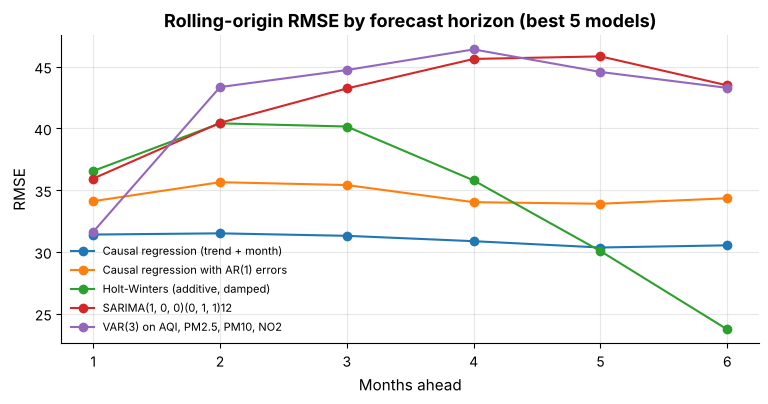

In [17]:
by_h = errs.groupby(["model", "h"])["err"].apply(lambda e: np.sqrt(np.mean(e ** 2))).unstack("model")
show = comp.index[:5]
fig, ax = plt.subplots(figsize=(9, 4))
for m in show:
    ax.plot(by_h.index, by_h[m], marker="o", label=m)
ax.set(title="Rolling-origin RMSE by forecast horizon (best 5 models)", xlabel="Months ahead", ylabel="RMSE")
ax.legend(fontsize=8)
save_figure(fig, "05_rmse_by_horizon"); plt.show()

**Which forecasting model is best?**

* **Winner: causal regression (trend + month dummies)**, with the lowest rolling-origin RMSE (31.0) and MAPE (11.8%),
  27.5% better than the seasonal naive benchmark, and the lowest RMSE on the 2019 test window except for its own
  AR(1)-error variant (test RMSE 29.0, MAPE 13.9%).
* The AR(1)-error version is best on the 6 test months (RMSE 26.3) but worse over the 19 rolling origins (34.6), so
  the extra parameter does not reliably help point forecasts; its value is honest standard errors.
* **Holt-Winters** (additive, damped trend) is a close second (rolling RMSE 35.0, 18% skill). **SARIMA** and **VAR**
  only tie the seasonal naive benchmark: with 54 months, their extra parameters cost as much as they gain.
* **Methods without seasonality fail badly:** naive, MA(3) and simple exponential smoothing have rolling MAPE of
  55-62%, and non-seasonal ARIMA 46%. SES chose a smoothing constant near 1, which makes it identical to the naive
  forecast. On a strongly seasonal series, ignoring seasonality more than doubles the error.
* **By horizon:** the causal regression's RMSE is flat at about 31 for every horizon, because its forecast depends on
  the calendar, not on the last observation. SARIMA and VAR errors grow from about 32-36 one month ahead to 43-46
  four to six months ahead. One month ahead the VAR (31.6) is as good as the causal model, so recent pollutant
  information helps only in the very short run. Holt-Winters is uneven (37 at 1 month, 24 at 6 months).
* The six 2019 test months: July was under-forecast (actual 145 vs 90, a late monsoon), October over-forecast (251
  vs 281); November and December were within 25 points.

## Part F: Final model, 6-month forecast for January to June 2020, and the COVID-19 check

In [18]:
BEST = comp.index[0]
print("selected model:", BEST)
fut_idx = pd.date_range("2020-01-01", periods=6, freq="MS")

def final_forecast(name):
    """Refit on all 60 months; return point forecast and 95% interval."""
    if name.startswith("SARIMA"):
        r = SARIMAX(y, order=SARIMA_ORDER, seasonal_order=SARIMA_SEAS).fit(disp=False)
        fr = r.get_forecast(6).summary_frame(alpha=.05)
        return fr["mean"].values, fr["mean_ci_lower"].values, fr["mean_ci_upper"].values, r
    if name.startswith("Holt-Winters"):
        r = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12,
                                 initialization_method="estimated").fit()
        sims = r.simulate(6, repetitions=5000, error="add", random_errors="bootstrap", random_state=SEED)
        return r.forecast(6).values, sims.quantile(.025, axis=1).values, sims.quantile(.975, axis=1).values, r
    if name == "Causal regression with AR(1) errors":
        r, Xh = fit_glsar(y)
        rho, sig = float(r.model.rho[0]), float(np.sqrt(r.scale))
        pt = MODELS[name](y, 6)
        # forecast-error SD of an AR(1) error process h steps ahead (parameter uncertainty ignored)
        sd = sig * np.sqrt(np.cumsum(rho ** (2 * np.arange(6))))
        return pt, pt - 1.96 * sd, pt + 1.96 * sd, r
    if name.startswith("Causal"):
        start = 6 if CAUSAL_VAR else 0
        Xh = causal_design(y.index[start:], CAUSAL_VAR)
        r = sm.OLS(y.iloc[start:], Xh).fit()
        Xf = causal_design(fut_idx, CAUSAL_VAR, src=monthly.reindex(monthly.index.union(fut_idx)))[Xh.columns]
        fr = r.get_prediction(Xf).summary_frame(alpha=.05)
        return fr["mean"].values, fr["obs_ci_lower"].values, fr["obs_ci_upper"].values, r
    # any other model: point forecast plus an empirical interval from rolling-origin errors at each horizon
    point = MODELS[name](y, 6)
    q_lo = errs[errs["model"] == name].groupby("h")["err"].quantile(.025).values
    q_hi = errs[errs["model"] == name].groupby("h")["err"].quantile(.975).values
    return point, point + q_lo, point + q_hi, None

point, lo, hi, final_res = final_forecast(BEST)
h20 = pd.read_csv(DATA_2020, parse_dates=["Date"]).set_index("Date")["AQI"].resample("MS").mean()
actual20 = h20.reindex(fut_idx)
fc_tab = pd.DataFrame({"forecast": point, "lower_95": lo, "upper_95": hi, "actual 2020 (not used)": actual20.values},
                      index=fut_idx)
fc_tab["actual - forecast"] = fc_tab["actual 2020 (not used)"] - fc_tab["forecast"]
fc_tab["inside 95% PI"] = fc_tab["actual 2020 (not used)"].between(fc_tab["lower_95"], fc_tab["upper_95"])
fc_tab.round(1)

selected model: Causal regression (trend + month)


,forecast,lower_95,upper_95,actual 2020 (not used),actual - forecast,inside 95% PI
2020-01-01,316.2,231.5,400.8,308.5,-7.7,True
2020-02-01,251.7,167.1,336.4,262.1,10.4,True
2020-03-01,185.4,100.7,270.0,135.8,-49.5,True
2020-04-01,220.9,136.3,305.6,113.0,-107.9,False
2020-05-01,226.1,141.5,310.8,148.6,-77.5,True
2020-06-01,159.0,74.4,243.7,125.7,-33.3,True


Jan-Feb 2020: mean error +1.3 AQI points (normal period)
Apr-Jun 2020: mean error -72.9 AQI points (-36% vs the no-lockdown forecast)


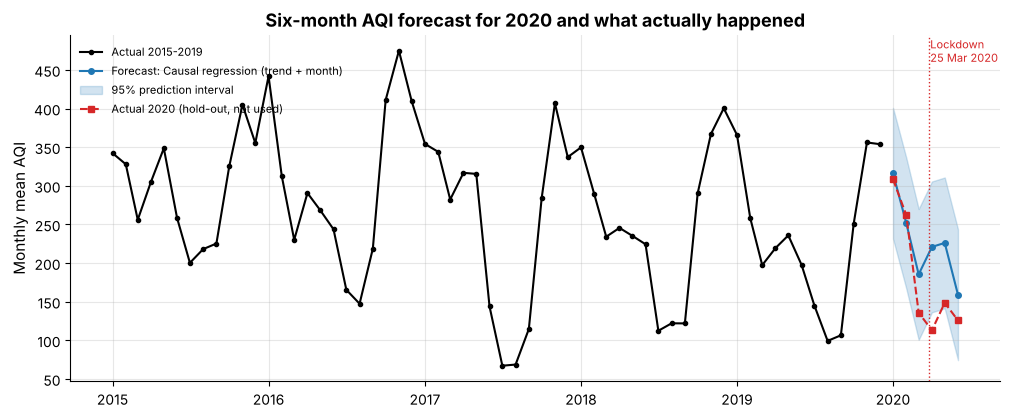

In [19]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y.index, y, "k-o", ms=3, label="Actual 2015-2019")
ax.plot(fut_idx, point, "C0-o", ms=4, label=f"Forecast: {BEST}")
ax.fill_between(fut_idx, lo, hi, color="C0", alpha=.2, label="95% prediction interval")
ax.plot(fut_idx, actual20, "C3--s", ms=5, label="Actual 2020 (hold-out, not used)")
ax.axvline(pd.Timestamp("2020-03-25"), color="C3", ls=":", lw=1)
ax.text(pd.Timestamp("2020-03-28"), ax.get_ylim()[1] * .93, "Lockdown\n25 Mar 2020", color="C3", fontsize=8)
ax.set(title="Six-month AQI forecast for 2020 and what actually happened", ylabel="Monthly mean AQI")
ax.legend(fontsize=8, loc="upper left")
save_figure(fig, "05_final_forecast"); plt.show()
pre = fc_tab.loc["2020-01":"2020-02"]
post = fc_tab.loc["2020-04":"2020-06"]
print(f"Jan-Feb 2020: mean error {pre['actual - forecast'].mean():+.1f} AQI points (normal period)")
print(f"Apr-Jun 2020: mean error {post['actual - forecast'].mean():+.1f} AQI points "
      f"({(post['actual 2020 (not used)'].sum() / post['forecast'].sum() - 1) * 100:+.0f}% vs the no-lockdown forecast)")

Durbin-Watson = 1.09
Ljung-Box on final-model residuals:
     lb_stat  lb_pvalue
6    13.551      0.035
12   32.873      0.001
Shapiro-Wilk normality p = 0.588


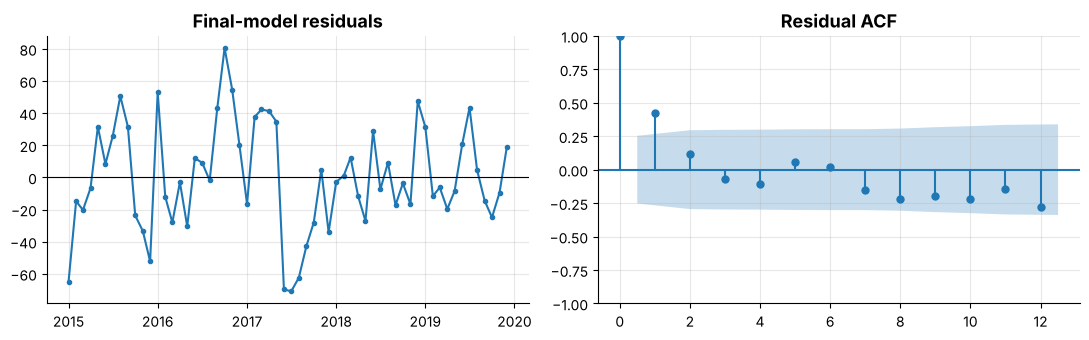

In [20]:
if final_res is not None and hasattr(final_res, "resid"):
    res_ = pd.Series(np.asarray(final_res.resid), index=y.index)
    res_ = res_.iloc[13:] if BEST.startswith("SARIMA") else res_
    lbf = acorr_ljungbox(res_, lags=[6, 12], return_df=True)
    print(f"Durbin-Watson = {sm.stats.durbin_watson(res_):.2f}")
    print("Ljung-Box on final-model residuals:\n", lbf.round(3))
    print(f"Shapiro-Wilk normality p = {stats.shapiro(res_)[1]:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(res_.index, res_, marker="."); ax[0].axhline(0, color="k", lw=.8); ax[0].set_title("Final-model residuals")
    plot_acf(res_, lags=12, ax=ax[1]); ax[1].set_title("Residual ACF")
    plt.tight_layout(); save_figure(fig, "05_final_residuals"); plt.show()

In [21]:
hist_rows = pd.DataFrame({"month": y.index.strftime("%Y-%m"), "actual": y.values, "forecast": np.nan,
                          "lower_95": np.nan, "upper_95": np.nan, "model": "", "segment": "history"})
test_rows = pd.DataFrame({"month": test.index.strftime("%Y-%m"), "actual": test.values, "forecast": test_fc[BEST],
                          "lower_95": np.nan, "upper_95": np.nan, "model": BEST, "segment": "test (fitted to 2019-06)"})
hist_rows = hist_rows[~hist_rows["month"].isin(test_rows["month"])]
fut_rows = pd.DataFrame({"month": fut_idx.strftime("%Y-%m"), "actual": np.nan, "forecast": point, "lower_95": lo,
                         "upper_95": hi, "model": BEST, "segment": "future"})
out = pd.concat([hist_rows, test_rows, fut_rows], ignore_index=True)
out["observed_2020"] = out["month"].map(dict(zip(fut_idx.strftime("%Y-%m"), actual20.values)))
out["test_rmse"] = comp.loc[BEST, "Test RMSE"]
out["test_mape"] = comp.loc[BEST, "Test MAPE %"]
out.round(2).to_csv(FORECAST_CSV, index=False)
print("saved", FORECAST_CSV.relative_to(ROOT), out.shape)
out.tail(8).round(1)

saved outputs/forecast_monthly.csv (66, 10)


,month,actual,forecast,lower_95,upper_95,model,segment,observed_2020,test_rmse,test_mape
58,2019-11,356.1,366.7,NaN,NaN,Causal regression (trend + month),test (fitted to 2019-06),NaN,29.0,13.9
59,2019-12,353.9,328.8,NaN,NaN,Causal regression (trend + month),test (fitted to 2019-06),NaN,29.0,13.9
60,2020-01,NaN,316.2,231.5,400.8,Causal regression (trend + month),future,308.5,29.0,13.9
61,2020-02,NaN,251.7,167.1,336.4,Causal regression (trend + month),future,262.1,29.0,13.9
62,2020-03,NaN,185.4,100.7,270.0,Causal regression (trend + month),future,135.8,29.0,13.9
63,2020-04,NaN,220.9,136.3,305.6,Causal regression (trend + month),future,113.0,29.0,13.9
64,2020-05,NaN,226.1,141.5,310.8,Causal regression (trend + month),future,148.6,29.0,13.9
65,2020-06,NaN,159.0,74.4,243.7,Causal regression (trend + month),future,125.7,29.0,13.9


**Final forecast and the COVID-19 natural experiment**

* The causal regression was refitted on all 60 months. Its 95% prediction intervals are about ±85 AQI points, which
  is wide compared with its rolling-origin RMSE of 31, so they are conservative rather than optimistic despite the
  residual autocorrelation (Durbin-Watson 1.09, Ljung-Box p = 0.001; residuals are normal, Shapiro-Wilk p = 0.59).
* **January-February 2020** (before COVID-19): actual 308.5 and 262.1 vs forecasts 316.2 and 251.7, an average error
  of just +1.3 AQI points. The model works when the world behaves normally.
* **April-June 2020** (lockdown from 25 March): actual AQI was **73 points (36%) below** the no-lockdown forecast on
  average. April (113 vs 221) fell outside the 95% interval. The forecast acts as a *counterfactual*: the gap is a
  rough estimate of the lockdown effect, the clearest evidence in the project that traffic and industry move Delhi's
  AQI. It is rough because 2020 weather also differed, and only April lies outside the interval.
* This is why 2020 was kept out of the models: it is a structural break, not noise.
* The forecast is saved to `outputs/forecast_monthly.csv` for the app.

## Part G: Daily ARMA model for next-day AQI
The monthly models answer "what will the coming season look like?". A different question is "what will AQI be
tomorrow?". Daily AQI is modelled as a **regression with ARMA errors**: a linear trend and three pairs of annual
Fourier terms (sin and cos of 2πk·day/365.25, k = 1, 2, 3) capture the slow seasonal cycle, and an ARMA(p, q) process
captures day-to-day persistence. Orders are chosen by AIC on 2015-2018; 2019 is the test year, forecast one day at a
time with the parameters frozen.

chosen daily model: ARMA(2,2) errors + trend + 3 Fourier pairs


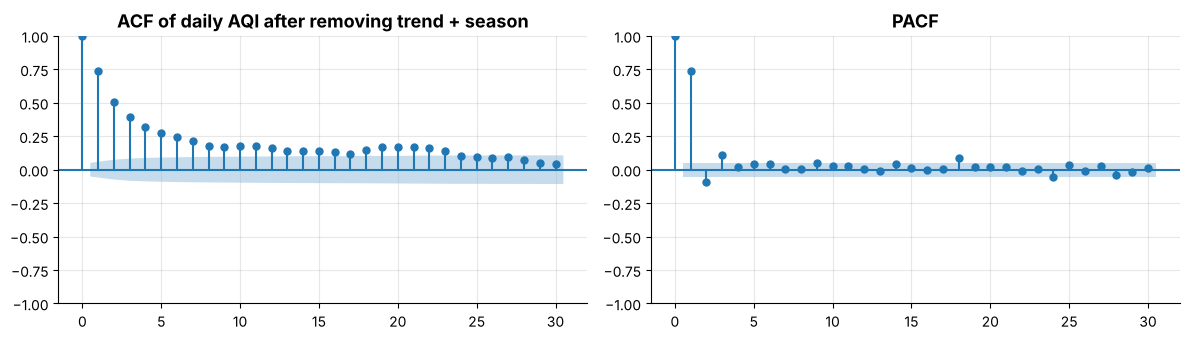

,ARMA,p,q,AIC,BIC
7,"(2,2)",2,2,15580.1,15648.8
10,"(3,2)",3,2,15581.4,15655.4
9,"(3,1)",3,1,15584.1,15652.8
8,"(3,0)",3,0,15588.3,15651.7
4,"(1,2)",1,2,15588.3,15651.7
6,"(2,1)",2,1,15595.3,15658.8


In [22]:
d_aqi = daily["AQI"].copy()
d_aqi.index.freq = "D"
tt = np.arange(len(d_aqi))
doy = d_aqi.index.dayofyear.values
Xf = pd.DataFrame({"trend": tt / 365.25}, index=d_aqi.index)
for k in (1, 2, 3):
    Xf[f"sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
    Xf[f"cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
tr_d = d_aqi.index.year <= 2018
y_dtr, X_dtr = d_aqi[tr_d], Xf[tr_d]

seas_fit = sm.OLS(y_dtr, sm.add_constant(X_dtr)).fit()
anom = seas_fit.resid
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(anom, lags=30, ax=ax[0]); ax[0].set_title("ACF of daily AQI after removing trend + season")
plot_pacf(anom, lags=30, ax=ax[1], method="ywm"); ax[1].set_title("PACF")
plt.tight_layout(); save_figure(fig, "05_daily_acf"); plt.show()

rows = []
for p, q in itertools.product(range(4), range(3)):
    if p == q == 0:
        continue
    r = SARIMAX(y_dtr, exog=sm.add_constant(X_dtr), order=(p, 0, q)).fit(disp=False)
    rows.append({"ARMA": f"({p},{q})", "p": p, "q": q, "AIC": r.aic, "BIC": r.bic})
arma_tab = pd.DataFrame(rows).sort_values("AIC")
P_D, Q_D = int(arma_tab.iloc[0]["p"]), int(arma_tab.iloc[0]["q"])
print(f"chosen daily model: ARMA({P_D},{Q_D}) errors + trend + 3 Fourier pairs")
arma_tab.head(6).round(1)

In [23]:
arma_d = SARIMAX(y_dtr, exog=sm.add_constant(X_dtr), order=(P_D, 0, Q_D)).fit(disp=False)
print(arma_d.summary().tables[1])
full = arma_d.apply(d_aqi, exog=sm.add_constant(Xf))       # same parameters, filter through 2019
one_step = full.get_prediction(start=d_aqi.index[~tr_d][0]).summary_frame(alpha=.05)
act19 = d_aqi[~tr_d]
persist = d_aqi.shift(1)[~tr_d]
clim = seas_fit.predict(sm.add_constant(Xf[~tr_d]))
cover = act19.between(one_step["mean_ci_lower"], one_step["mean_ci_upper"]).mean()
day_tab = pd.DataFrame({
    "One-step ARMA + season": [rmse(act19, one_step["mean"]), mape(act19, one_step["mean"])],
    "Persistence (tomorrow = today)": [rmse(act19, persist), mape(act19, persist)],
    "Seasonal climatology only": [rmse(act19, clim), mape(act19, clim)]}, index=["2019 RMSE", "2019 MAPE %"]).T
print(f"95% interval coverage in 2019: {cover:.1%}")
save_table(day_tab.round(3).reset_index(names="Model"), "daily_next_day_forecast")
day_tab.round(2)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        314.5960     14.826     21.219      0.000     285.538     343.654
trend        -19.6971      7.010     -2.810      0.005     -33.437      -5.957
sin1          11.3841     11.243      1.013      0.311     -10.652      33.421
cos1         104.1898     10.763      9.680      0.000      83.094     125.285
sin2         -71.1393     10.484     -6.785      0.000     -91.688     -50.590
cos2           8.4904      9.466      0.897      0.370     -10.062      27.043
sin3           8.5499      8.941      0.956      0.339      -8.975      26.074
cos3          -2.5447      8.368     -0.304      0.761     -18.946      13.857
ar.L1          1.4322      0.069     20.796      0.000       1.297       1.567
ar.L2         -0.4598      0.057     -8.101      0.000      -0.571      -0.349
ma.L1         -0.6186      0.069     -8.915      0.0

,2019 RMSE,2019 MAPE %
One-step ARMA + season,50.19,17.26
Persistence (tomorrow = today),53.99,17.72
Seasonal climatology only,80.45,31.49


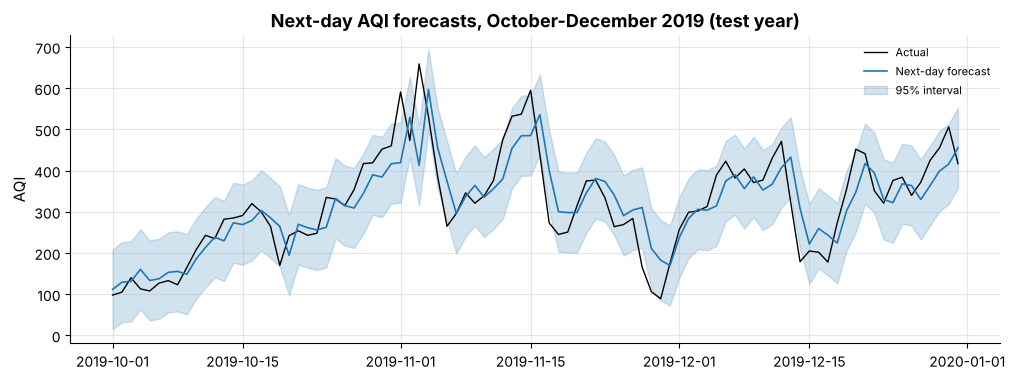

In [24]:
fig, ax = plt.subplots(figsize=(12, 4))
win = slice("2019-10-01", "2019-12-31")
ax.plot(act19[win].index, act19[win], "k-", lw=1, label="Actual")
ax.plot(one_step.loc[win].index, one_step.loc[win, "mean"], "C0-", lw=1.2, label="Next-day forecast")
ax.fill_between(one_step.loc[win].index, one_step.loc[win, "mean_ci_lower"], one_step.loc[win, "mean_ci_upper"],
                color="C0", alpha=.2, label="95% interval")
ax.set(title="Next-day AQI forecasts, October-December 2019 (test year)", ylabel="AQI"); ax.legend(fontsize=8)
save_figure(fig, "05_daily_forecast"); plt.show()

**Next-day forecasting: findings**

* After removing trend and season, the daily ACF decays slowly and the PACF has two large spikes, pointing to a
  low-order ARMA. AIC chooses **ARMA(2,2)** errors (AR coefficients 1.43 and -0.46: very persistent).
* The fitted seasonal part matches the monthly analysis (the first annual harmonic cos1 = 104, highly significant),
  and the trend is -19.7 AQI per year, almost exactly the -19 per year from the monthly causal regression.
* **2019 one-day-ahead test:** RMSE 50.2 and MAPE 17.3%, compared with 54.0 for persistence ("tomorrow = today") and
  80.5 for seasonal climatology alone: 7% better than persistence and 38% better than climatology. Persistence is a
  tough benchmark because daily AQI is so autocorrelated (lag-1 r = 0.90).
* The 95% intervals cover 92.9% of 2019 days, close to the nominal 95%; the small shortfall comes from sudden
  episodes (Diwali, stubble-fire smoke) that no linear model can anticipate without outside information such as
  weather or fire counts.